# 02 — Error Analysis (deployed model: XGBoost)
Input: `results/test_predictions.csv` (test rows + each model's probability), written by `src/evaluate.py`.
We use the **same threshold chosen on the validation set**. Nothing here changes the model.

Questions:
1. Who are the **false negatives** (missed diabetics), and how do they differ from the people we catch?
2. Who are the **false positives**?
3. Is performance **fair** across sex, age and income groups?
4. How many errors are **low-confidence** (close to the threshold)?
5. Are some cases **hard for every model**?

In [1]:
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "src"))
from config import DEPLOYED_MODEL, FIGURES_DIR, MODELS_DIR, RESULTS_DIR, TARGET

COLOR_NO_DIABETES, COLOR_DIABETES, TEXT_MUTED = "#2a78d6", "#eb6834", "#52514e"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})

def save(fig, name):
    fig.savefig(FIGURES_DIR / f"{name}.png", bbox_inches="tight")

df = pd.read_csv(RESULTS_DIR / "test_predictions.csv")
threshold = joblib.load(MODELS_DIR / f"{DEPLOYED_MODEL}.joblib")["threshold"]
df["proba"] = df[f"proba_{DEPLOYED_MODEL}"]
df["predicted"] = (df["proba"] >= threshold).astype(int)

def outcome(row):
    if row[TARGET] == 1:
        return "TP" if row["predicted"] == 1 else "FN"
    return "FP" if row["predicted"] == 1 else "TN"

df["outcome"] = df.apply(outcome, axis=1)
print(f"Threshold (from validation): {threshold:.3f}")
df["outcome"].value_counts()

Threshold (from validation): 0.639


outcome
TN    24071
FP     5086
TP     3266
FN     1999
Name: count, dtype: int64

## 1. How well separated are the two classes? (probability distribution)

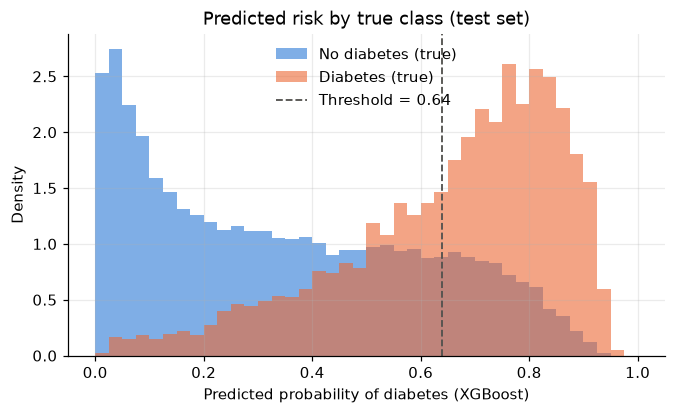

In [2]:
fig, ax = plt.subplots(figsize=(7, 3.8))
bins = np.linspace(0, 1, 41)
ax.hist(df.loc[df[TARGET] == 0, "proba"], bins=bins, alpha=0.6, color=COLOR_NO_DIABETES, label="No diabetes (true)", density=True)
ax.hist(df.loc[df[TARGET] == 1, "proba"], bins=bins, alpha=0.6, color=COLOR_DIABETES, label="Diabetes (true)", density=True)
ax.axvline(threshold, ls="--", color=TEXT_MUTED, lw=1.2, label=f"Threshold = {threshold:.2f}")
ax.set_xlabel("Predicted probability of diabetes (XGBoost)")
ax.set_ylabel("Density")
ax.set_title("Predicted risk by true class (test set)")
ax.legend(frameon=False)
save(fig, "err_01_probability_distribution")
plt.show()

**Reading it:** the two classes overlap heavily in the middle. That overlap is where the errors come from:
many people with diabetes give the same survey answers as people without it.

## 2. Profile of each outcome group: who gets missed?

In [3]:
profile_cols = ["GenHlth", "Age", "BMI", "HighBP", "HighChol", "ComorbidityCount",
                "DiffWalk", "CholCheck", "PhysActivity", "Income", "Education", "proba"]
profile = df.groupby("outcome")[profile_cols].mean().loc[["TP", "FN", "FP", "TN"]].round(2)
profile.insert(0, "count", df["outcome"].value_counts())
profile.to_csv(RESULTS_DIR / "error_outcome_profiles.csv")
profile

,count,GenHlth,Age,BMI,HighBP,HighChol,ComorbidityCount,DiffWalk,CholCheck,PhysActivity,Income,Education,proba
outcome,,,,,,,,,,,,,
TP,3266,3.70,9.67,34.22,0.90,0.80,2.14,0.51,1.00,0.56,4.76,4.60,0.79
FN,1999,2.71,8.95,28.60,0.51,0.49,1.12,0.17,0.99,0.72,5.82,4.93,0.45
FP,5086,3.48,9.77,32.62,0.87,0.73,1.98,0.42,1.00,0.60,4.96,4.66,0.75
TN,24071,2.27,7.46,27.13,0.30,0.33,0.70,0.10,0.94,0.78,6.23,5.11,0.26


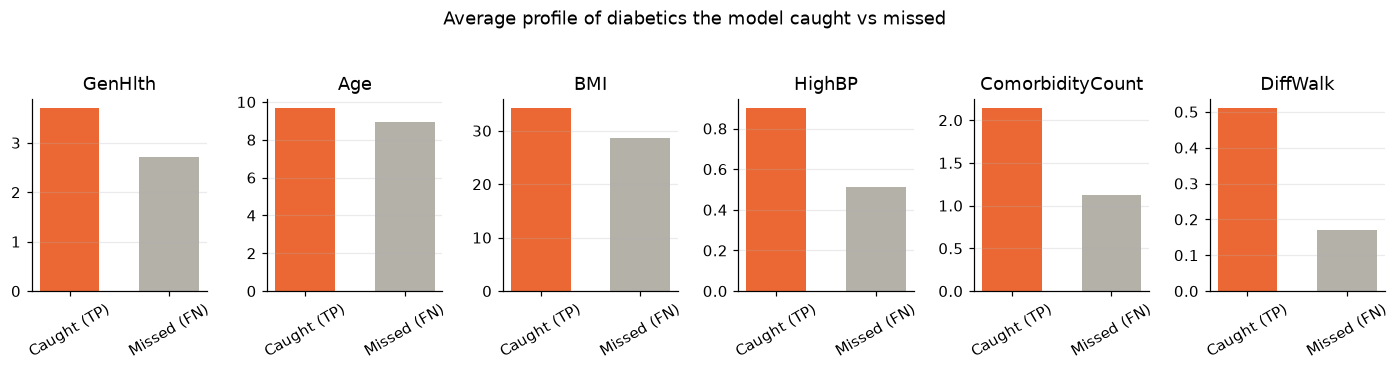

In [4]:
# Side-by-side: missed diabetics (FN) vs caught diabetics (TP), on the features that matter most.
compare = ["GenHlth", "Age", "BMI", "HighBP", "ComorbidityCount", "DiffWalk"]
tp, fn = profile.loc["TP", compare], profile.loc["FN", compare]

fig, axes = plt.subplots(1, len(compare), figsize=(13, 3.2))
for ax, col in zip(axes, compare):
    ax.bar(["Caught (TP)", "Missed (FN)"], [tp[col], fn[col]], color=[COLOR_DIABETES, "#b3b1a8"], width=0.6)
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=30)
    ax.grid(axis="x", visible=False)
fig.suptitle("Average profile of diabetics the model caught vs missed", y=1.04)
fig.tight_layout()
save(fig, "err_02_fn_vs_tp_profile")
plt.show()

In [5]:
fn_rows = df[df["outcome"] == "FN"]
healthy_looking = (fn_rows["GenHlth"] <= 2) & (fn_rows["HighBP"] == 0)
print(f"False negatives: {len(fn_rows):,}")
print(f"  ...rating their health 'excellent/very good' AND no high blood pressure: "
      f"{healthy_looking.sum():,} ({healthy_looking.mean():.1%})")
print(f"  ...with BMI < 30 (not obese): {(fn_rows['BMI'] < 30).mean():.1%}")
print(f"  ...aged under 55 (Age group <= 7): {(fn_rows['Age'] <= 7).mean():.1%}")

False negatives: 1,999
  ...rating their health 'excellent/very good' AND no high blood pressure: 347 (17.4%)
  ...with BMI < 30 (not obese): 64.6%
  ...aged under 55 (Age group <= 7): 29.3%


## 3. Fairness check: performance by subgroup

In [6]:
def group_metrics(data, group_col):
    rows = []
    for group, part in data.groupby(group_col, observed=True):
        tp = ((part[TARGET] == 1) & (part["predicted"] == 1)).sum()
        fn = ((part[TARGET] == 1) & (part["predicted"] == 0)).sum()
        fp = ((part[TARGET] == 0) & (part["predicted"] == 1)).sum()
        tn = ((part[TARGET] == 0) & (part["predicted"] == 0)).sum()
        rows.append({"attribute": group_col, "group": group, "n": len(part),
                     "prevalence": part[TARGET].mean(),
                     "recall": tp / (tp + fn) if tp + fn else np.nan,
                     "false_positive_rate": fp / (fp + tn) if fp + tn else np.nan,
                     "precision": tp / (tp + fp) if tp + fp else np.nan})
    return pd.DataFrame(rows)

df["Sex group"] = df["Sex"].map({0: "Female", 1: "Male"})
df["Age band"] = pd.cut(df["Age"], bins=[0, 5, 9, 13], labels=["18-44", "45-64", "65+"])
df["Income band"] = pd.cut(df["Income"], bins=[0, 3, 6, 8], labels=["Low (<$20k)", "Middle", "High ($50k+)"])
df["Education band"] = pd.cut(df["Education"], bins=[0, 4, 6], labels=["High school or less", "Some college+"])

fairness = pd.concat([group_metrics(df, c) for c in ["Sex group", "Age band", "Income band", "Education band"]])
fairness = fairness.round(3)
fairness.to_csv(RESULTS_DIR / "error_subgroup_metrics.csv", index=False)
fairness

,attribute,group,n,prevalence,recall,false_positive_rate,precision
0,Sex group,Female,19075,0.142,0.616,0.155,0.397
1,Sex group,Male,15347,0.167,0.625,0.200,0.385
0,Age band,18-44,7385,0.043,0.281,0.025,0.340
1,Age band,45-64,14453,0.154,0.597,0.158,0.409
2,Age band,65+,12584,0.216,0.679,0.303,0.382
0,Income band,Low (<$20k),5652,0.247,0.764,0.336,0.427
1,Income band,Middle,12083,0.170,0.643,0.212,0.383
2,Income band,High ($50k+),16687,0.109,0.485,0.103,0.366
0,Education band,High school or less,11155,0.196,0.684,0.254,0.397
1,Education band,Some college+,23267,0.132,0.575,0.139,0.386


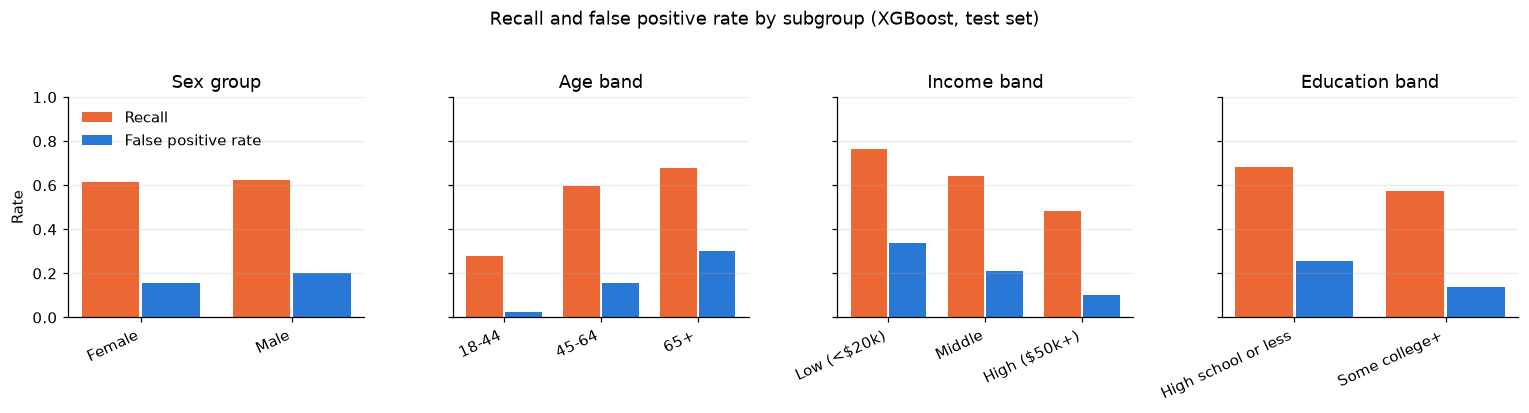

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6), sharey=True)
for ax, attribute in zip(axes, fairness["attribute"].unique()):
    part = fairness[fairness["attribute"] == attribute]
    x = np.arange(len(part))
    ax.bar(x - 0.2, part["recall"], width=0.38, color=COLOR_DIABETES, label="Recall")
    ax.bar(x + 0.2, part["false_positive_rate"], width=0.38, color=COLOR_NO_DIABETES, label="False positive rate")
    ax.set_xticks(x, part["group"].astype(str), rotation=25, ha="right")
    ax.set_title(attribute)
    ax.set_ylim(0, 1)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Rate")
axes[0].legend(frameon=False, loc="upper left")
fig.suptitle("Recall and false positive rate by subgroup (XGBoost, test set)", y=1.03)
fig.tight_layout()
save(fig, "err_03_subgroup_fairness")
plt.show()

**Reading it:** recall that changes across groups is often driven by different **prevalence** (older and lower-income groups have
more diabetes, so the model flags them more). That is not automatically unfair, but it must be reported. Younger people are
the group where diabetes is most often missed, which matches the false-negative profile above.

## 4. Low-confidence predictions (close to the threshold)

In [8]:
margin = 0.10
near = (df["proba"] - threshold).abs() < margin
error = df[TARGET] != df["predicted"]
print(f"Predictions within ±{margin} of the threshold: {near.sum():,} ({near.mean():.1%} of test rows)")
print(f"Error rate near the threshold:  {error[near].mean():.1%}")
print(f"Error rate further away:        {error[~near].mean():.1%}")
print(f"Share of all errors that are near the threshold: {(error & near).sum() / error.sum():.1%}")

Predictions within ±0.1 of the threshold: 6,931 (20.1% of test rows)
Error rate near the threshold:  46.7%
Error rate further away:        14.0%
Share of all errors that are near the threshold: 45.7%


**Use in the app:** predictions near the threshold are shown as "Moderate / uncertain" rather than a hard yes/no.

## 5. Hard cases: missed by every model?

In [9]:
thresholds = {name: joblib.load(MODELS_DIR / f"{name}.joblib")["threshold"]
              for name in ["logistic_regression", "random_forest", "xgboost"]}
positives = df[df[TARGET] == 1]
missed = pd.DataFrame({name: positives[f"proba_{name}"] < t for name, t in thresholds.items()})
n_models_missing = missed.sum(axis=1)
print("Diabetics missed by how many of the 3 models:")
print(n_models_missing.value_counts().sort_index().rename("count").to_string())
print(f"\nMissed by ALL three models: {(n_models_missing == 3).sum():,} "
      f"({(n_models_missing == 3).mean():.1%} of diabetics)")
print(f"Of XGBoost's false negatives, also missed by both other models: "
      f"{(n_models_missing[missed['xgboost']] == 3).mean():.1%}")

Diabetics missed by how many of the 3 models:
0    2946
1     333
2     301
3    1685

Missed by ALL three models: 1,685 (32.0% of diabetics)
Of XGBoost's false negatives, also missed by both other models: 84.3%


If almost every XGBoost miss is also missed by LR and RF, the problem is the **information in the data** (no glucose/HbA1c),
not the choice of algorithm. A better model alone will not fix it.

## 6. Error-analysis conclusions — write in your own words for the report
Use only the numbers printed above.
1. **Who is missed:** …
2. **Who is falsely flagged:** …
3. **Fairness:** recall by age/income/sex …
4. **Uncertainty:** …% of errors are near the threshold → …
5. **Hard cases:** …% of misses are shared by all three models → the limit is the data, not the algorithm.